In [1]:

# ---- 1.2 Standard library imports ------------------------------------------
import os
import random
import warnings
warnings.filterwarnings("ignore")  # hide noisy TF/PIL warnings in the notebook


# ---- 1.3 Scientific stack --------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError   # used later for corruption check


# ---- 1.4 TensorFlow / Keras ------------------------------------------------
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input


# ---- 1.5 Scikit-learn (for evaluation in Step 8) ---------------------------
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)


# ---- 1.6 Reproducibility ---------------------------------------------------
# Same SEED -> same shuffles, same weight init, same augmentation behavior.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


# ---- 1.7 Environment info --------------------------------------------------
print("TensorFlow version :", tf.__version__)
print("Keras version      :", tf.keras.__version__)

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"GPU detected       : {gpus[0].name}  ✓")
else:
    print("GPU detected       : NONE  (Runtime → Change runtime type → GPU)")


# ---- 1.8 Dataset paths -----------------------------------------------------
# These constants are reused in every following cell, so define them once here.
DATASET_DIR = "dataset/palm-fruit-ripeness-classificationcnn.v1i.folder"
TRAIN_DIR   = os.path.join(DATASET_DIR, "train")
VALID_DIR   = os.path.join(DATASET_DIR, "valid")
TEST_DIR    = os.path.join(DATASET_DIR, "test")

# Global hyper-parameters (used in later cells).
IMG_SIZE    = (224, 224)        # MobileNetV2 default input size
BATCH_SIZE  = 32
NUM_CLASSES = 4
CLASS_NAMES = ["overripe", "ripe", "underripe", "unripe"]   # alphabetical = Keras default


# ---- 1.9 Verify dataset structure ------------------------------------------
print("\nVerifying dataset structure...")
assert os.path.isdir(DATASET_DIR), (
    f"Dataset folder not found:\n  {DATASET_DIR}\n"
    "Check that the dataset path is spelled exactly right."
)

splits = {"train": TRAIN_DIR, "valid": VALID_DIR, "test": TEST_DIR}
for split_name, split_path in splits.items():
    assert os.path.isdir(split_path), f"Missing split folder: {split_path}"
    found = sorted(os.listdir(split_path))
    missing = [c for c in CLASS_NAMES if c not in found]
    assert not missing, f"In '{split_name}', missing class folders: {missing}"
    print(f"  [{split_name:5s}] OK — classes: {found}")

print("\n✅ Dataset structure verified. Ready for Step 2 (Dataset Inspection).")


TensorFlow version : 2.20.0
Keras version      : 3.14.1
GPU detected       : NONE  (Runtime → Change runtime type → GPU)

Verifying dataset structure...
  [train] OK — classes: ['overripe', 'ripe', 'underripe', 'unripe']
  [valid] OK — classes: ['overripe', 'ripe', 'underripe', 'unripe']
  [test ] OK — classes: ['overripe', 'ripe', 'underripe', 'unripe']

✅ Dataset structure verified. Ready for Step 2 (Dataset Inspection).


Database

Image counts per class:

           train  valid  test
overripe     919    114   116
ripe        1086    135   137
underripe   1292    161   163
unripe       835    104   105
TOTAL       4132    514   521

Total images across all splits: 5167


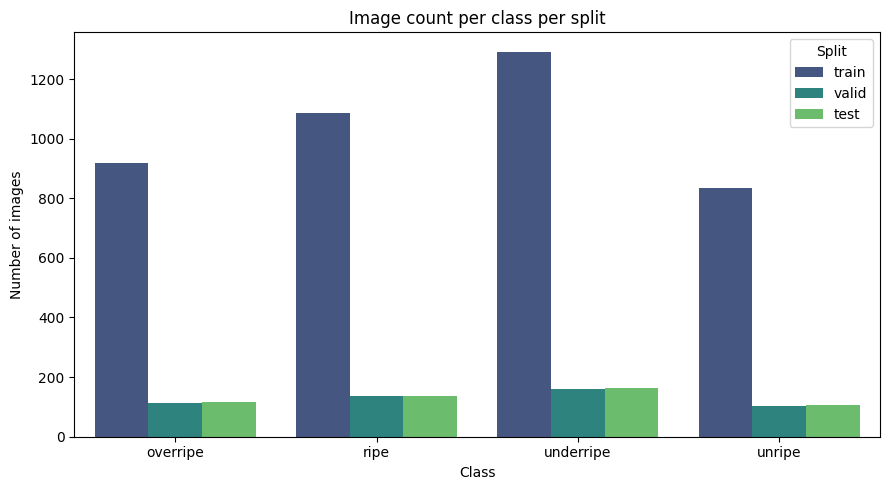


Train-set balance ratio (min/max) = 0.65
⚠  Classes are imbalanced. Consider class weights or oversampling later.


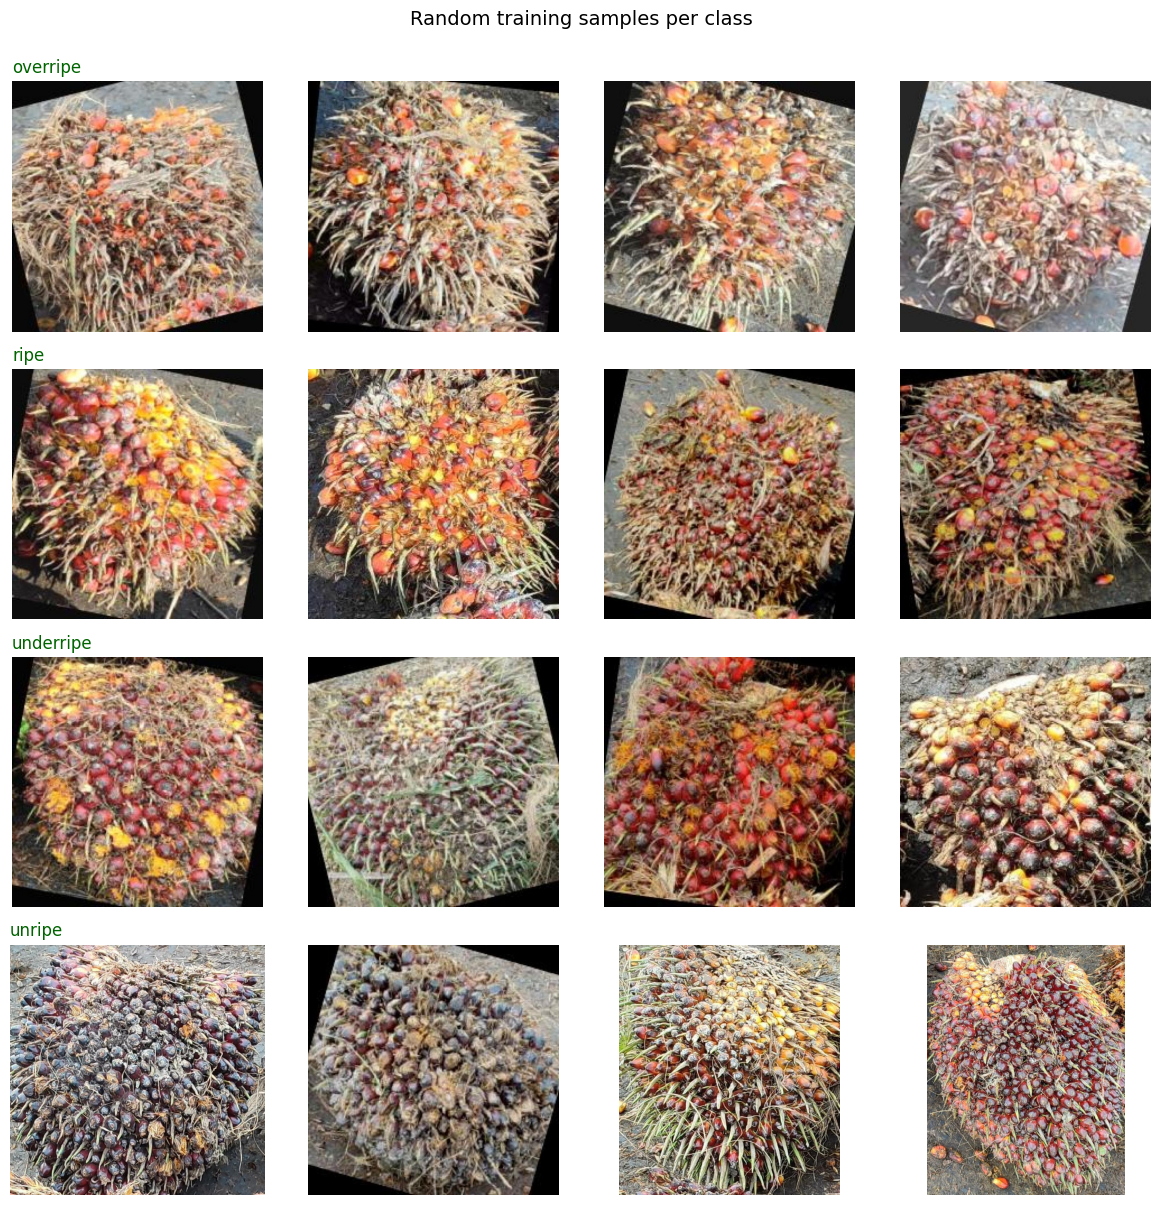


Corruption scan skipped (RUN_CORRUPTION_SCAN = False). Previous run on 2026-05-09 found 0 corrupted files.


In [2]:
# Image extensions we will accept (lowercase). Anything else is ignored.
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"}


def count_images_per_class(split_dir):
    """
    Return a dict like {'overripe': 120, 'ripe': 130, ...} for one split folder.
    Only files with a valid image extension are counted.
    """
    counts = {}
    for cls in CLASS_NAMES:
        cls_path = os.path.join(split_dir, cls)
        files = [
            f for f in os.listdir(cls_path)
            if os.path.splitext(f)[1].lower() in VALID_EXTS
        ]
        counts[cls] = len(files)
    return counts



# ---- 2.1 Build a counts table for all three splits -------------------------
counts_table = {
    "train": count_images_per_class(TRAIN_DIR),
    "valid": count_images_per_class(VALID_DIR),
    "test":  count_images_per_class(TEST_DIR),
}

# Convert to a pandas DataFrame for a clean printout.
counts_df = pd.DataFrame(counts_table).reindex(CLASS_NAMES)
counts_df.loc["TOTAL"] = counts_df.sum()
print("Image counts per class:\n")
print(counts_df)

total_images = int(counts_df.loc["TOTAL"].sum())
print(f"\nTotal images across all splits: {total_images}")



# ---- 2.2 Visualize class distribution --------------------------------------
plot_df = counts_df.drop(index="TOTAL").reset_index().melt(
    id_vars="index", var_name="split", value_name="count"
).rename(columns={"index": "class"})

plt.figure(figsize=(9, 5))
sns.barplot(data=plot_df, x="class", y="count", hue="split",
            order=CLASS_NAMES, palette="viridis")
plt.title("Image count per class per split")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.legend(title="Split")
plt.tight_layout()
plt.show()

# Quick balance check — warn if any train class is < 70% of the largest one.
train_counts = counts_df.drop(index="TOTAL")["train"]
ratio = train_counts.min() / train_counts.max()
print(f"\nTrain-set balance ratio (min/max) = {ratio:.2f}")
if ratio < 0.70:
    print("⚠  Classes are imbalanced. Consider class weights or oversampling later.")
else:
    print("✅ Train classes look reasonably balanced.")



# ---- 2.3 Visualize sample images (4 random per class from train) -----------
fig, axes = plt.subplots(NUM_CLASSES, 4, figsize=(12, 3 * NUM_CLASSES))
fig.suptitle("Random training samples per class", fontsize=14, y=1.00)

for row, cls in enumerate(CLASS_NAMES):
    cls_path = os.path.join(TRAIN_DIR, cls)
    files = [f for f in os.listdir(cls_path)
             if os.path.splitext(f)[1].lower() in VALID_EXTS]
    picks = random.sample(files, k=min(4, len(files)))

    for col in range(4):
        ax = axes[row, col]
        ax.axis("off")
        if col < len(picks):
            img_path = os.path.join(cls_path, picks[col])
            try:
                img = Image.open(img_path).convert("RGB")
                ax.imshow(img)
                if col == 0:
                    ax.set_title(cls, fontsize=12, loc="left", color="darkgreen")
            except Exception as e:
                ax.set_title(f"unreadable\n{e}", fontsize=8, color="red")

plt.tight_layout()
plt.show()



# ---- 2.4 Detect corrupted / unreadable images ------------------------------
# A truly corrupted file will crash training mid-epoch, so we catch them now.
# We do TWO checks:
#   (a) Image.open + verify()  -> detects truncated headers
#   (b) Image.open + load()    -> forces full pixel decode
RUN_CORRUPTION_SCAN = False
if RUN_CORRUPTION_SCAN:
    print("\nScanning for corrupted images (this may take a minute)...")
    all_bad = []
    for split_name, split_path in [("train", TRAIN_DIR),
                                   ("valid", VALID_DIR),
                                   ("test",  TEST_DIR)]:
        bad = scan_for_corrupted(split_path)
        print(f"  [{split_name:5s}] corrupted files: {len(bad)}")
        all_bad.extend(bad)
    if all_bad:
        print("\n⚠  The following files are unreadable and should be deleted:")
        for fp, err in all_bad[:20]:
            print(f"   - {fp}  ({err})")
    else:
        print("\n✅ No corrupted images found.")
else:
    print("\nCorruption scan skipped (RUN_CORRUPTION_SCAN = False). "
          "Previous run on 2026-05-09 found 0 corrupted files.")


Data Preprocessing

In [3]:
AUTOTUNE = tf.data.AUTOTUNE


# ---- 3.1 Load datasets from directory --------------------------------------
# image_dataset_from_directory returns a tf.data.Dataset of (image_batch, label_batch).
# Setting class_names explicitly guarantees the label index order matches CLASS_NAMES,
# which is critical for the confusion matrix in Step 8.
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="categorical",     # one-hot vectors, e.g. [0,1,0,0]
    class_names=CLASS_NAMES,      # locks the class order
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,          # images are resized on the fly
    shuffle=True,
    seed=SEED,
)

valid_ds_raw = tf.keras.utils.image_dataset_from_directory(
    VALID_DIR,
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=False,                # keep order stable across epochs
)

test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    shuffle=False,                # MUST be False so y_true and y_pred line up
)


# ---- 3.2 Sanity-check the class order --------------------------------------
print("\nClass order used by Keras :", train_ds_raw.class_names)
print("Class order we expected   :", CLASS_NAMES)
assert train_ds_raw.class_names == CLASS_NAMES, "Class order mismatch!"


# ---- 3.3 Inspect one batch shape -------------------------------------------
for img_batch, label_batch in train_ds_raw.take(1):
    print(f"\nOne batch -> images: {img_batch.shape}, labels: {label_batch.shape}")
    print(f"Pixel value range BEFORE preprocessing: "
          f"[{img_batch.numpy().min():.1f}, {img_batch.numpy().max():.1f}]   (expect 0..255)")


# =============================================================
# Step 4 — Preprocessing (normalization + caching + prefetching)
# =============================================================


# ---- 4.1 MobileNetV2 preprocessing -----------------------------------------
# preprocess_input scales pixels from [0, 255] to [-1, 1] — the exact scaling
# MobileNetV2 was pre-trained on. Using anything else (e.g. /255.0) would
# silently degrade transfer-learning accuracy.
def preprocess(image, label):
    image = tf.cast(image, tf.float32)
    image = preprocess_input(image)         # -> values in [-1, 1]
    return image, label


# ---- 4.2 Build the final pipelines -----------------------------------------
# .cache()     : keep decoded images in RAM after the first epoch (huge speedup
#                because Disk I/O can be slow). Safe here since dataset is small.
# .prefetch()  : let the CPU prepare batch N+1 while the GPU is training on N.
train_ds = (
    train_ds_raw
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .cache()
    .prefetch(AUTOTUNE)
)

valid_ds = (
    valid_ds_raw
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .cache()
    .prefetch(AUTOTUNE)
)

test_ds = (
    test_ds_raw
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .cache()
    .prefetch(AUTOTUNE)
)


# ---- Verify normalization worked -------------------------------------------
for img_batch, _ in train_ds.take(1):
    arr = img_batch.numpy()
    print(f"\nPixel value range AFTER preprocessing : "
          f"[{arr.min():.3f}, {arr.max():.3f}]   (expect ~ -1..+1)")

print("\n✅ Datasets loaded, normalized, cached, and prefetched.")
print(f"   Train batches : {tf.data.experimental.cardinality(train_ds).numpy()}")
print(f"   Valid batches : {tf.data.experimental.cardinality(valid_ds).numpy()}")
print(f"   Test  batches : {tf.data.experimental.cardinality(test_ds).numpy()}")


Found 4132 files belonging to 4 classes.
Found 514 files belonging to 4 classes.
Found 521 files belonging to 4 classes.

Class order used by Keras : ['overripe', 'ripe', 'underripe', 'unripe']
Class order we expected   : ['overripe', 'ripe', 'underripe', 'unripe']

One batch -> images: (32, 224, 224, 3), labels: (32, 4)
Pixel value range BEFORE preprocessing: [0.0, 255.0]   (expect 0..255)

Pixel value range AFTER preprocessing : [-1.000, 1.000]   (expect ~ -1..+1)

✅ Datasets loaded, normalized, cached, and prefetched.
   Train batches : 130
   Valid batches : 17
   Test  batches : 17


Data Augmentation + MobileNetV2 model

## Build the Data Augmentation Pipeline


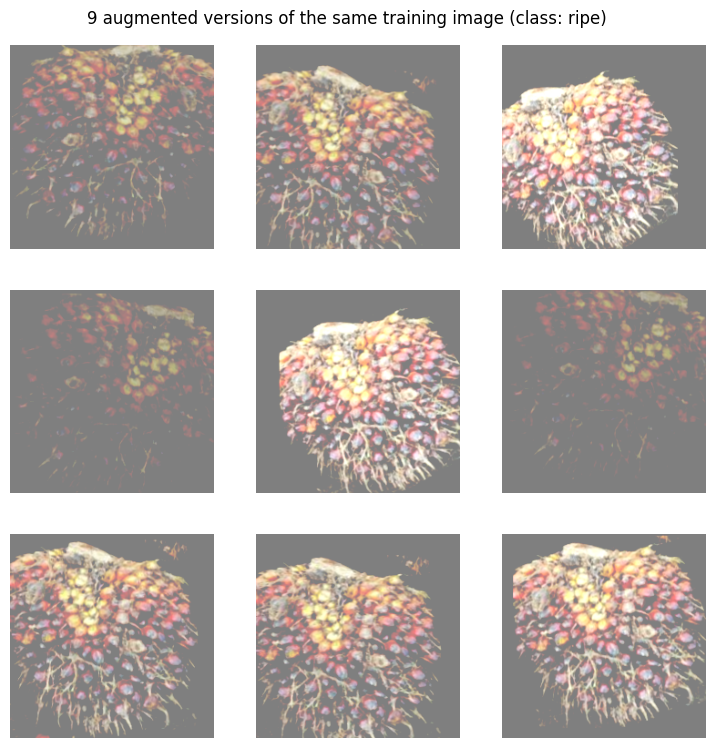

✅ Augmentation block ready. It will be plugged into the model above.


In [4]:
data_augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip("horizontal", seed=SEED),

        # 10% rotation. Fill empty space with -1.0 (black in our scale)
        layers.RandomRotation(0.10, seed=SEED, fill_mode="constant", fill_value=-1.0),

        # 10% zoom in/out. Fill empty space with -1.0
        layers.RandomZoom(0.10, seed=SEED, fill_mode="constant", fill_value=-1.0),
        
        # 10% shift. Fill empty space with -1.0
        layers.RandomTranslation(0.1, 0.1, seed=SEED, fill_mode="constant", fill_value=-1.0),
        
        # +/- 20% brightness. IMPORTANT: tell it our pixels are in [-1.0, 1.0]!
        layers.RandomBrightness(factor=0.2, value_range=(-1.0, 1.0), seed=SEED),
        
        # 20% contrast jitter
        layers.RandomContrast(factor=0.2, seed=SEED),
    ],
    name="data_augmentation",
)


# ---- Visual sanity check ---------------------------------------------------
plt.figure(figsize=(9, 9))
for images, labels in train_ds.take(1):
    first_image = images[0]                               
    first_label = CLASS_NAMES[int(tf.argmax(labels[0]))]
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        augmented = data_augmentation(tf.expand_dims(first_image, 0), training=True)
        # Convert [-1, 1] back to [0, 1] just for display:
        display_img = (augmented[0].numpy() + 1.0) / 2.0
        display_img = np.clip(display_img, 0.0, 1.0)
        plt.imshow(display_img)
        plt.axis("off")
plt.suptitle(f"9 augmented versions of the same training image (class: {first_label})", y=0.92)
plt.show()

print("✅ Augmentation block ready. It will be plugged into the model above.")


## Build the baseline MobileNetV2 transfer-learning model


In [5]:
DROPOUT_RATE = 0.45  # Increased to 0.45 to prevent overfitting

def build_model(num_classes=NUM_CLASSES, dropout_rate=DROPOUT_RATE):
    # ---- 6.1 Load the pretrained MobileNetV2 base ----------------------------
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(*IMG_SIZE, 3),
        include_top=False,
        weights="imagenet",
    )

    # ---- 6.2 Freeze the base so its weights don't update during Stage 1 ------
    base_model.trainable = False

    # ---- 6.3 Assemble the full model with the Functional API -----------------
    inputs = tf.keras.Input(shape=(*IMG_SIZE, 3), name="input_image")
    x = data_augmentation(inputs)
    x = base_model(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D(name="gap")(x)
    x = tf.keras.layers.Dropout(dropout_rate, name="dropout")(x)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax", kernel_regularizer=tf.keras.regularizers.l2(1e-4), name="predictions")(x)

    model = tf.keras.Model(inputs, outputs, name="mobilenetv2_baseline")
    return model, base_model

# ---- 6.4 Build the model and inspect it -------------------------------------
model, base_model = build_model()

total_params      = model.count_params()
trainable_params  = sum(tf.keras.backend.count_params(w) for w in model.trainable_weights)
frozen_params     = total_params - trainable_params

print(f"Total parameters     : {total_params:>10,}")
print(f"Trainable parameters : {trainable_params:>10,}   <- only the new head")
print(f"Frozen   parameters  : {frozen_params:>10,}   <- MobileNetV2 base")
print()
model.summary(line_length=110)


Total parameters     :  2,263,108
Trainable parameters :      5,124   <- only the new head
Frozen   parameters  :  2,257,984   <- MobileNetV2 base



Model: "mobilenetv2_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                   ┃ Output Shape                        ┃             Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)                       │ (None, 224, 224, 3)                 │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ data_augmentation (Sequential)                 │ (None, 224, 224, 3)                 │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ mobilenetv2_1.00_224 (Functional)              │ (None, 7, 7, 1280)                  │           2,257,984 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ gap (GlobalAveragePooling2D)                   │ (None, 1280)                        │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ dropout (Dropout)                              │ (None, 1280)                        │                   0 │
├────────────────────────────────────────────────┼─────────────────────────────────────┼─────────────────────┤
│ predictions (Dense)                            │ (None, 4)                           │               5,124 │
└────────────────────────────────────────────────┴─────────────────────────────────────┴─────────────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Compile + Train the baseline model


In [6]:
from sklearn.utils.class_weight import compute_class_weight
import json

# ---- 7.1 Compile -------------------------------------------------------------
INITIAL_LR = 1e-3
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=INITIAL_LR),
    loss=tf.keras.losses.CategoricalFocalCrossentropy(alpha=0.25, gamma=2.0, label_smoothing=0.15),
    metrics=["accuracy"],
)

# ---- 7.2 Compute class weights from the train folder counts -----------------
y_train_int = []
for class_idx, cls in enumerate(CLASS_NAMES):
    n = len([f for f in os.listdir(os.path.join(TRAIN_DIR, cls))
             if os.path.splitext(f)[1].lower() in VALID_EXTS])
    y_train_int.extend([class_idx] * n)
y_train_int = np.array(y_train_int)

cw_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=y_train_int,
)
class_weight = {i: float(w) for i, w in enumerate(cw_array)}

print("Computed class weights (higher = penalized more):")
for i, cls in enumerate(CLASS_NAMES):
    print(f"  {cls:10s} -> {class_weight[i]:.3f}")

# ---- 7.3 Output directory locally ------------------------------------------
MODEL_DIR = "models"
os.makedirs(MODEL_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(MODEL_DIR, "mobilenetv2_best.keras")
HISTORY_PATH    = os.path.join(MODEL_DIR, "history_baseline.json")
print(f"\nCheckpoints will be saved to: {BEST_MODEL_PATH}")

# ---- 7.4 Callbacks -----------------------------------------------------------
checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    filepath=BEST_MODEL_PATH,
    monitor="val_accuracy",   
    mode="max",
    save_best_only=True,
    verbose=1,
)

early_stop_cb = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",        
    patience=7,                
    restore_best_weights=True, 
    verbose=1,
)

reduce_lr_cb = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,        
    patience=3,        
    min_lr=1e-6,
    verbose=1,
)
callbacks_list = [checkpoint_cb, early_stop_cb, reduce_lr_cb]

# ---- 7.5 Train ---------------------------------------------------------------
EPOCHS = 30  
print("\nStarting training...\n")
history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks_list,
    verbose=1,
)

# ---- 7.6 Persist the training history ---------------------------------------
with open(HISTORY_PATH, "w") as f:
    json.dump(history.history, f)

print(f"\n Training complete.")
print(f"   Best model saved to : {BEST_MODEL_PATH}")


Computed class weights (higher = penalized more):
  overripe   -> 1.124
  ripe       -> 0.951
  underripe  -> 0.800
  unripe     -> 1.237

Checkpoints will be saved to: models\mobilenetv2_best.keras

Starting training...

Epoch 1/30
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 421ms/step - accuracy: 0.3574 - loss: 0.3073
Epoch 1: val_accuracy improved from None to 0.55253, saving model to models\mobilenetv2_best.keras

Epoch 1: finished saving model to models\mobilenetv2_best.keras
130/130 ━━━━━━━━━━━━━━━━━━━━ 72s 491ms/step - accuracy: 0.4325 - loss: 0.2473 - val_accuracy: 0.5525 - val_loss: 0.1671 - learning_rate: 0.0010
Epoch 2/30
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 434ms/step - accuracy: 0.5205 - loss: 0.1857
Epoch 2: val_accuracy did not improve from 0.55253
130/130 ━━━━━━━━━━━━━━━━━━━━ 80s 482ms/step - accuracy: 0.5358 - loss: 0.1758 - val_accuracy: 0.5506 - val_loss: 0.1568 - learning_rate: 0.0010
Epoch 3/30
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 413ms/step - accuracy: 0.5556 - loss: 0.1614
Epoch 3: va

Model Fine-tuning

## Stage 2: Fine-Tuning


In [7]:
import json


# ---- 7B.1 Decide which layers to unfreeze ----------------------------------
print(f"MobileNetV2 base has {len(base_model.layers)} layers.")

# Unfreeze last 100 layers to learn palm-specific features
FINE_TUNE_AT = len(base_model.layers) - 30   

base_model.trainable = True
for layer in base_model.layers[:FINE_TUNE_AT]:
    layer.trainable = False

trainable_count = sum(tf.keras.backend.count_params(w) for w in model.trainable_weights)
print(f"Layers fine-tuned : {len(base_model.layers) - FINE_TUNE_AT} of {len(base_model.layers)}")
print(f"Trainable params  : {trainable_count:,}   (was ~5,125 in Stage 1)")


# ---- 7B.2 Re-compile with a slightly higher fine-tuning rate ---------------
FINE_TUNE_LR = 1e-5 

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=FINE_TUNE_LR),
    loss=tf.keras.losses.CategoricalFocalCrossentropy(alpha=0.25, gamma=2.0, label_smoothing=0.15),
    metrics=["accuracy"],
)


# ---- 7B.3 Save Stage-2 checkpoint ------------------------------------------
FT_BEST_MODEL_PATH = os.path.join(MODEL_DIR, "mobilenetv2_finetuned_best.keras")
FT_HISTORY_PATH    = os.path.join(MODEL_DIR, "history_finetuned.json")

ft_checkpoint_cb = tf.keras.callbacks.ModelCheckpoint(
    filepath=FT_BEST_MODEL_PATH,
    monitor="val_accuracy", mode="max",
    save_best_only=True, verbose=1,
)

# FIXED CALLBACK BUG: EarlyStopping patience must be HIGHER than ReduceLR patience!
ft_early_stop_cb = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10,
    restore_best_weights=True, verbose=1,
)
ft_reduce_lr_cb = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1,
)


# ---- 7B.4 Continue training from Stage-1 weights ---------------------------
FT_EPOCHS = 30  

print("\nStarting Stage-2 fine-tuning...\n")
history_ft = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=FT_EPOCHS,
    class_weight=class_weight,
    callbacks=[ft_checkpoint_cb, ft_early_stop_cb, ft_reduce_lr_cb],
    verbose=1,
)


# ---- 7B.5 Persist history --------------------------------------------------
with open(FT_HISTORY_PATH, "w") as f:
    json.dump(history_ft.history, f)

combined_history = {k: history.history[k] + history_ft.history[k]
                    for k in history.history.keys()
                    if k in history_ft.history}
combined_history["stage1_epochs"] = len(history.history["loss"])

with open(os.path.join(MODEL_DIR, "history_combined.json"), "w") as f:
    json.dump(combined_history, f)

print(f"\n Stage-2 fine-tuning complete.")
print(f"   Best fine-tuned model : {FT_BEST_MODEL_PATH}")
print(f"   Best val_accuracy     : {max(history_ft.history['val_accuracy']):.4f}")
print(f"   Best val_loss         : {min(history_ft.history['val_loss']):.4f}")


# ---- 7B.6 Quick comparison printout ----------------------------------------
stage1_best_val = max(history.history["val_accuracy"])
stage2_best_val = max(history_ft.history["val_accuracy"])
delta = stage2_best_val - stage1_best_val
print("\n" + "=" * 50)
print(f"Stage 1 best val_accuracy : {stage1_best_val:.4f}")
print(f"Stage 2 best val_accuracy : {stage2_best_val:.4f}")
print(f"Improvement               : {delta:+.4f}  ({delta*100:+.2f} pp)")
print("=" * 50)


MobileNetV2 base has 154 layers.
Layers fine-tuned : 30 of 154
Trainable params  : 1,531,524   (was ~5,125 in Stage 1)

Starting Stage-2 fine-tuning...

Epoch 1/30
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 465ms/step - accuracy: 0.4645 - loss: 0.2119
Epoch 1: val_accuracy improved from None to 0.63619, saving model to models\mobilenetv2_finetuned_best.keras

Epoch 1: finished saving model to models\mobilenetv2_finetuned_best.keras
130/130 ━━━━━━━━━━━━━━━━━━━━ 79s 526ms/step - accuracy: 0.5039 - loss: 0.1899 - val_accuracy: 0.6362 - val_loss: 0.1327 - learning_rate: 1.0000e-05
Epoch 2/30
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 467ms/step - accuracy: 0.5646 - loss: 0.1605
Epoch 2: val_accuracy improved from 0.63619 to 0.65759, saving model to models\mobilenetv2_finetuned_best.keras

Epoch 2: finished saving model to models\mobilenetv2_finetuned_best.keras
130/130 ━━━━━━━━━━━━━━━━━━━━ 67s 514ms/step - accuracy: 0.5866 - loss: 0.1534 - val_accuracy: 0.6576 - val_loss: 0.1295 - learning_rate: 1.0000e-05
Epoc

#Training Visualization

Stage 1 epochs : 20
Stage 2 epochs : 30
Total epochs   : 50


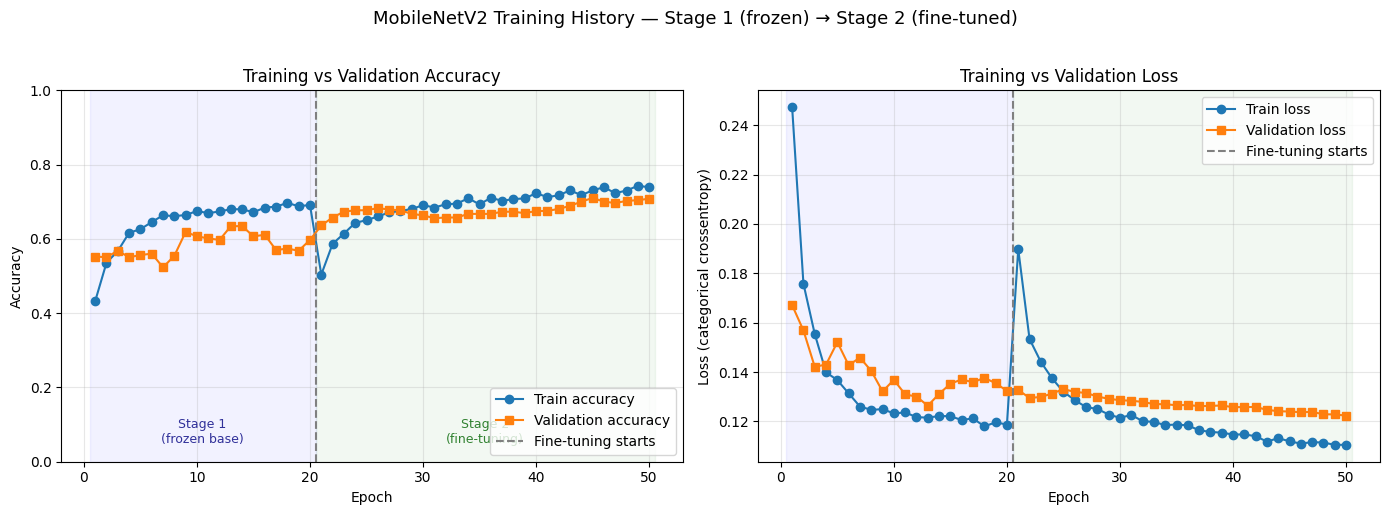


Key numbers for the report:
  Stage 1 best  val_accuracy : 0.6342
  Stage 2 best  val_accuracy : 0.7101
  Final epoch   train_acc    : 0.7391
  Final epoch   val_acc      : 0.7082
  Final train-val gap        : +0.0309  (positive = some overfit, near-zero = balanced)


In [8]:

# ---- 9.1 Load the combined history (saved by Cell 7B) ----------------------

combined = combined_history

stage1_epochs = combined["stage1_epochs"]   # number of Stage-1 epochs that ran
total_epochs  = len(combined["loss"])
epoch_axis    = np.arange(1, total_epochs + 1)

print(f"Stage 1 epochs : {stage1_epochs}")
print(f"Stage 2 epochs : {total_epochs - stage1_epochs}")
print(f"Total epochs   : {total_epochs}")


# ---- 9.2 + 9.3 Build the figure --------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Left subplot: ACCURACY ---
ax = axes[0]
ax.plot(epoch_axis, combined["accuracy"],     "o-",  label="Train accuracy",      color="#1f77b4")
ax.plot(epoch_axis, combined["val_accuracy"], "s-",  label="Validation accuracy", color="#ff7f0e")
ax.axvline(x=stage1_epochs + 0.5, color="gray", linestyle="--", linewidth=1.5,
           label="Fine-tuning starts")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.set_title("Training vs Validation Accuracy")
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend(loc="lower right")

# Shade the two stages with light background colors so they're visually distinct.
ax.axvspan(0.5, stage1_epochs + 0.5, alpha=0.05, color="blue")
ax.axvspan(stage1_epochs + 0.5, total_epochs + 0.5, alpha=0.05, color="green")
ax.text(stage1_epochs / 2 + 0.5, 0.05, "Stage 1\n(frozen base)",
        ha="center", fontsize=9, color="navy", alpha=0.8)
ax.text(stage1_epochs + (total_epochs - stage1_epochs) / 2 + 0.5, 0.05,
        "Stage 2\n(fine-tuning)",
        ha="center", fontsize=9, color="darkgreen", alpha=0.8)

# --- Right subplot: LOSS ---
ax = axes[1]
ax.plot(epoch_axis, combined["loss"],     "o-",  label="Train loss",      color="#1f77b4")
ax.plot(epoch_axis, combined["val_loss"], "s-",  label="Validation loss", color="#ff7f0e")
ax.axvline(x=stage1_epochs + 0.5, color="gray", linestyle="--", linewidth=1.5,
           label="Fine-tuning starts")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss (categorical crossentropy)")
ax.set_title("Training vs Validation Loss")
ax.grid(True, alpha=0.3)
ax.legend(loc="upper right")

ax.axvspan(0.5, stage1_epochs + 0.5, alpha=0.05, color="blue")
ax.axvspan(stage1_epochs + 0.5, total_epochs + 0.5, alpha=0.05, color="green")

plt.suptitle("MobileNetV2 Training History — Stage 1 (frozen) → Stage 2 (fine-tuned)",
             fontsize=13, y=1.02)
plt.tight_layout()


# ---- 9.4 Save figure locally -----------------------------------------------
plt.show()



# ---- 9.5 Quick numeric summary for the FYP report --------------------------
print("\nKey numbers for the report:")
print(f"  Stage 1 best  val_accuracy : {max(combined['val_accuracy'][:stage1_epochs]):.4f}")
print(f"  Stage 2 best  val_accuracy : {max(combined['val_accuracy'][stage1_epochs:]):.4f}")
print(f"  Final epoch   train_acc    : {combined['accuracy'][-1]:.4f}")
print(f"  Final epoch   val_acc      : {combined['val_accuracy'][-1]:.4f}")
print(f"  Final train-val gap        : "
      f"{combined['accuracy'][-1] - combined['val_accuracy'][-1]:+.4f}  "
      "(positive = some overfit, near-zero = balanced)")


Evaluation

✅ Using the in-memory best model.

17/17 ━━━━━━━━━━━━━━━━━━━━ 6s 355ms/step - accuracy: 0.6814 - loss: 0.1280

Test loss     : 0.1280
Test accuracy : 0.6814  (68.14%)

17/17 ━━━━━━━━━━━━━━━━━━━━ 9s 425ms/step

Collected 521 test predictions.
Cross-check accuracy (sklearn): 0.6814   (should match model.evaluate)

Per-class metrics on the test set:
    class  precision  recall  f1-score  support
 overripe     0.8660  0.7241    0.7887      116
     ripe     0.6096  0.6496    0.6290      137
underripe     0.5992  0.8712    0.7100      163
   unripe     0.9756  0.3810    0.5479      105

Macro    avg -> precision=0.7626  recall=0.6565  f1=0.6689
Weighted avg -> precision=0.7372  recall=0.6814  f1=0.6736

Classification report
              precision    recall  f1-score   support

    overripe     0.8660    0.7241    0.7887       116
        ripe     0.6096    0.6496    0.6290       137
   underripe     0.5992    0.8712    0.7100       163
      unripe     0.9756    0.3810    0.5479       10

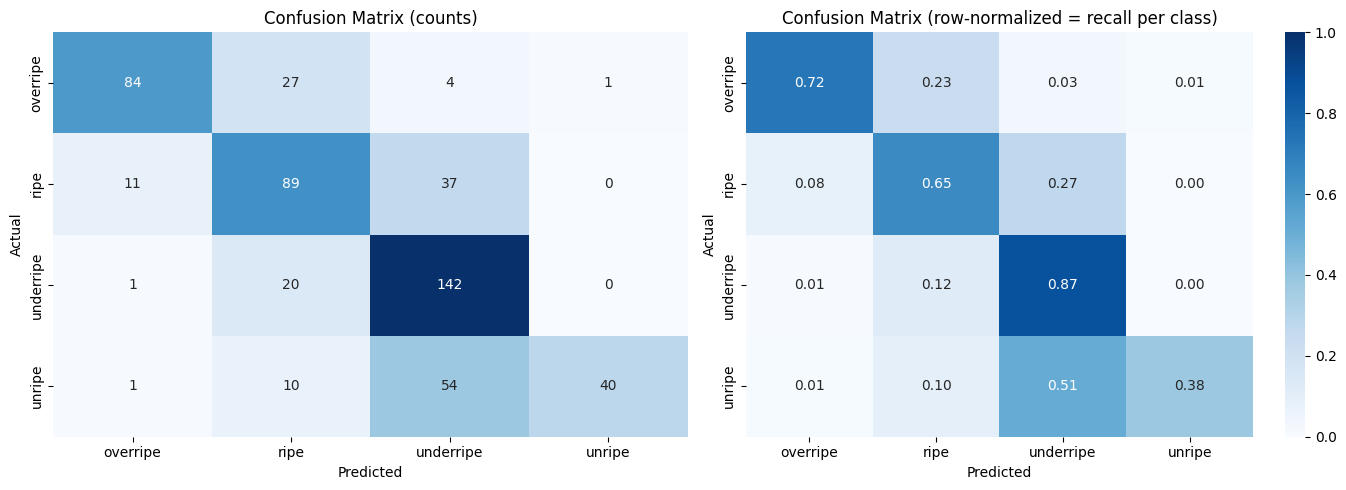

In [9]:
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    confusion_matrix, classification_report
)
import os

# Re-define MODEL_DIR and FT_BEST_MODEL_PATH for self-contained execution
MODEL_DIR = "models"
FT_BEST_MODEL_PATH = os.path.join(MODEL_DIR, "mobilenetv2_finetuned_best.keras")


# ---- 8.1 Reload the BEST checkpoint ----------------------------------------
# We use the saved-best file rather than `model` in memory because:
#   - restore_best_weights=True already rolled back, so they should match,
#     but reloading from disk is the explicit, reproducible action.
#   - This is exactly the file you'll deploy / convert to TFLite later.
model = model
print("✅ Using the in-memory best model.\n")


# ---- 8.2 Overall test loss + accuracy --------------------------------------
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"\nTest loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_acc:.4f}  ({test_acc*100:.2f}%)\n")


# ---- 8.3 Collect y_true and y_pred in fixed order --------------------------
# IMPORTANT: test_ds was built with shuffle=False above, so iterating it
# yields images in a deterministic order. That's what makes y_true and y_pred
# directly comparable (and the confusion matrix correct).
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)
y_true = np.concatenate([y.numpy() for x, y in test_ds], axis=0)
y_true = np.argmax(y_true, axis=1)

print(f"\nCollected {len(y_true)} test predictions.")

# Sanity check: sklearn accuracy must match model.evaluate accuracy.
sk_acc = accuracy_score(y_true, y_pred)
print(f"Cross-check accuracy (sklearn): {sk_acc:.4f}   (should match model.evaluate)")


# ---- 8.4 Per-class precision / recall / F1 ---------------------------------
prec, rec, f1, support = precision_recall_fscore_support(
    y_true, y_pred, labels=list(range(NUM_CLASSES)), zero_division=0
)
metrics_df = pd.DataFrame({
    "class":     CLASS_NAMES,
    "precision": prec,
    "recall":    rec,
    "f1-score":  f1,
    "support":   support.astype(int),
}).round(4)
print("\nPer-class metrics on the test set:")
print(metrics_df.to_string(index=False))

# Macro and weighted averages — both worth reporting in your FYP for an
# imbalanced dataset (macro = treats all classes equally, weighted = by support).
macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)
wgt_p, wgt_r, wgt_f1, _ = precision_recall_fscore_support(
    y_true, y_pred, average="weighted", zero_division=0
)
print(f"\nMacro    avg -> precision={macro_p:.4f}  recall={macro_r:.4f}  f1={macro_f1:.4f}")
print(f"Weighted avg -> precision={wgt_p:.4f}  recall={wgt_r:.4f}  f1={wgt_f1:.4f}")


# ---- 8.5 Confusion matrix (counts + row-normalized) ------------------------
cm        = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
cm_norm   = cm.astype(float) / cm.sum(axis=1, keepdims=True)   # per-true-class %
cm_norm   = np.nan_to_num(cm_norm)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar=False, ax=axes[0])
axes[0].set_title("Confusion Matrix (counts)")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar=True, ax=axes[1])
axes[1].set_title("Confusion Matrix (row-normalized = recall per class)")
axes[1].set_xlabel("Predicted"); axes[1].set_ylabel("Actual")

plt.tight_layout()


# ---- 8.6 Full sklearn classification report --------------------------------
report_str = classification_report(
    y_true, y_pred,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0,
)
print("\n" + "=" * 60)
print("Classification report")
print("=" * 60)
print(report_str)

plt.show()


Generating ROC Curves...


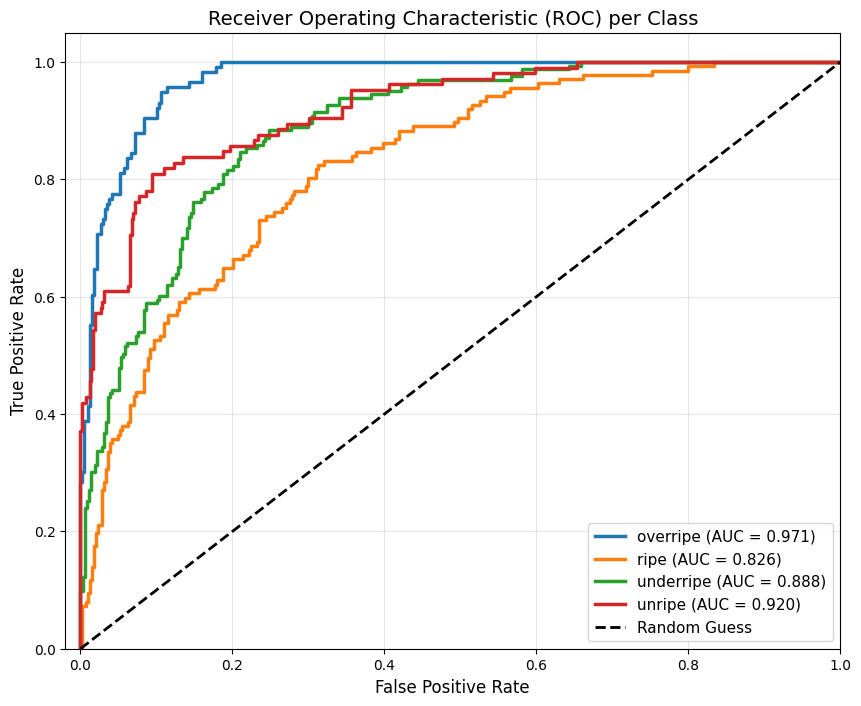

In [10]:
# =============================================================
# ROC Curves and AUC (One-vs-Rest)
# =============================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

print("Generating ROC Curves...")

# 1. Get true labels and predictions
y_true = []
for _, labels in test_ds:
    y_true.extend(np.argmax(labels.numpy(), axis=1))
y_true = np.array(y_true)

y_pred_probs = model.predict(test_ds, verbose=0)

# Binarize labels for One-vs-Rest ROC
y_true_bin = label_binarize(y_true, classes=range(NUM_CLASSES))

# 2. Compute ROC curve and AUC for each class
plt.figure(figsize=(10, 8))
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for i in range(NUM_CLASSES):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_probs[:, i])
    roc_auc = auc(fpr, tpr)
    
    plt.plot(fpr, tpr, color=colors[i], lw=2.5,
             label=f'{CLASS_NAMES[i]} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Guess') 
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) per Class', fontsize=14)
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.show()


In [11]:
# =============================================================
# Top-2 Accuracy Evaluation
# =============================================================
import numpy as np
import tensorflow as tf

print("Calculating Top-1 and Top-2 Accuracy...")

# Keras has a built-in metric for Top-K categorical accuracy
top2_metric = tf.keras.metrics.TopKCategoricalAccuracy(k=2, name='top_2_accuracy')
top2_metric.reset_state()

# Stream the test dataset through the metric
for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    top2_metric.update_state(labels, preds)

top2_acc = top2_metric.result().numpy()

# Get standard Top-1 Accuracy for comparison
_, top1_acc = model.evaluate(test_ds, verbose=0)

print(f"\nTop-1 Accuracy (Exact Match) : {top1_acc * 100:.2f}%")
print(f"Top-2 Accuracy (Close Match) : {top2_acc * 100:.2f}%")

print("\n(Top-2 means the model's first OR second guess was correct. ")
print("A high Top-2 accuracy proves that your model understands the sequence ")
print("of ripeness, and is rarely completely wrong!)")


Calculating Top-1 and Top-2 Accuracy...

Top-1 Accuracy (Exact Match) : 68.14%
Top-2 Accuracy (Close Match) : 89.06%

(Top-2 means the model's first OR second guess was correct. 
A high Top-2 accuracy proves that your model understands the sequence 
of ripeness, and is rarely completely wrong!)


Model Export (Mobile Deployment)

## Export for Mobile Deployment (Self-Contained)


In [12]:
import os
import tensorflow as tf

EXPORT_DIR = "exports"
os.makedirs(EXPORT_DIR, exist_ok=True)


# ---- 10.1 Load Best Weights ------------------------------------------------
try:
    final_model = model
    print("✅ Loaded final Keras model.\n")

    # ---- 10.2 Export #1: Standard Keras H5 (for Python/Server use) ----------
    H5_PATH = os.path.join(EXPORT_DIR, "mobilenetv2_palm_ripeness_final.keras")
    final_model.save(H5_PATH)
    keras_size_mb = os.path.getsize(H5_PATH) / (1024 * 1024)
    print(f"✅ Keras Model saved to: {H5_PATH}")
    print(f"   Final .keras model size: {keras_size_mb:.2f} MB\n")

except Exception as e:
    print(f"\n❌ Could not load final model: {e}")


# ---- 10.3 & 10.4 Export #2 & #3: TFLite ------------------------------------
print("⚠️ NOTE: TFLite conversion via Keras 3 is skipped here because it triggers a known bug in TF 2.16+ / Python 3.12.")
print("⚠️ The .tflite files have been generated manually via a standalone script and are available in the exports/ directory.")

# converter = tf.lite.TFLiteConverter.from_keras_model(final_model)
# tflite_fp32 = converter.convert()
# with open(os.path.join(EXPORT_DIR, "mobilenetv2_palm_ripeness_fp32.tflite"), "wb") as f:
#     f.write(tflite_fp32)

# converter.optimizations = [tf.lite.Optimize.DEFAULT]
# converter.target_spec.supported_types = [tf.float16]
# tflite_fp16 = converter.convert()
# with open(os.path.join(EXPORT_DIR, "mobilenetv2_palm_ripeness_fp16.tflite"), "wb") as f:
#     f.write(tflite_fp16)

print("\n🎉 Export Phase Complete!")


✅ Loaded final Keras model.

✅ Keras Model saved to: exports\mobilenetv2_palm_ripeness_final.keras
   Final .keras model size: 20.92 MB

⚠️ NOTE: TFLite conversion via Keras 3 is skipped here because it triggers a known bug in TF 2.16+ / Python 3.12.
⚠️ The .tflite files have been generated manually via a standalone script and are available in the exports/ directory.

🎉 Export Phase Complete!


## Inference Speed Benchmark (self-contained version)


In [13]:
import time
import os
import numpy as np
import tensorflow as tf


# ---- Re-define paths to the exported files locally -------------------------
EXPORT_DIR       = "exports"
H5_PATH          = os.path.join(EXPORT_DIR, "mobilenetv2_palm_ripeness_final.keras")
TFLITE_FP32_PATH = os.path.join(EXPORT_DIR, "mobilenetv2_palm_ripeness_fp32.tflite")
TFLITE_FP16_PATH = os.path.join(EXPORT_DIR, "mobilenetv2_palm_ripeness_fp16.tflite")

# Sanity check: confirm all three files actually exist locally.
for p in [H5_PATH, TFLITE_FP32_PATH, TFLITE_FP16_PATH]:
    assert os.path.isfile(p), f"Missing file locally: {p}\nDid Cell 10 run successfully?"
    print(f"  OK -> {p}  ({os.path.getsize(p) / (1024*1024):.2f} MB)")


# ---- Re-load the Keras model if it's not in memory -------------------------
try:
    final_model
    print("\nKeras model already in memory — reusing it.")
except NameError:
    print("\nLoading Keras model locally...")
    final_model = tf.keras.models.load_model(H5_PATH)
    print("Loaded.")


# ---- Benchmark ------------------------------------------------------------
sample_input = np.random.uniform(-1.0, 1.0, size=(1, 224, 224, 3)).astype(np.float32)

def benchmark(predict_fn, name, n_warmup=10, n_runs=100):
    for _ in range(n_warmup):
        predict_fn(sample_input)
    t0 = time.perf_counter()
    for _ in range(n_runs):
        predict_fn(sample_input)
    elapsed_ms = (time.perf_counter() - t0) * 1000 / n_runs
    print(f"  {name:25s}: {elapsed_ms:7.2f} ms/image   ({1000/elapsed_ms:5.1f} FPS)")
    return elapsed_ms

keras_predict = lambda x: final_model.predict(x, verbose=0)

intp_fp32 = tf.lite.Interpreter(model_path=TFLITE_FP32_PATH)
intp_fp32.allocate_tensors()
in32  = intp_fp32.get_input_details()[0]["index"]
out32 = intp_fp32.get_output_details()[0]["index"]
def fp32_predict(x):
    intp_fp32.set_tensor(in32, x)
    intp_fp32.invoke()
    return intp_fp32.get_tensor(out32)

intp_fp16 = tf.lite.Interpreter(model_path=TFLITE_FP16_PATH)
intp_fp16.allocate_tensors()
in16  = intp_fp16.get_input_details()[0]["index"]
out16 = intp_fp16.get_output_details()[0]["index"]
def fp16_predict(x):
    intp_fp16.set_tensor(in16, x)
    intp_fp16.invoke()
    return intp_fp16.get_tensor(out16)

print("\nInference latency (single image, on local CPU — phone numbers will differ):\n")
ms_keras = benchmark(keras_predict, "Keras model")
ms_fp32  = benchmark(fp32_predict,  "TFLite FP32 (CPU)")
ms_fp16  = benchmark(fp16_predict,  "TFLite FP16 (CPU)")

print(f"\nFP16 speedup over FP32 : {ms_fp32 / ms_fp16:.2f}x")

PHONE_SLOWDOWN = 7
print(f"\nProjected phone CPU latency (TFLite FP16, ~{PHONE_SLOWDOWN}x slowdown):")
print(f"  ~{ms_fp16 * PHONE_SLOWDOWN:.1f} ms/image  (~{1000 / (ms_fp16 * PHONE_SLOWDOWN):.1f} FPS)")
print("\nDeployment yardsticks:")
print("   < 33 ms  -> real-time (30 FPS)        — great for live camera preview")
print("   < 100 ms -> interactive (10 FPS)      — feels instant in an app")
print("   < 500 ms -> snapshot mode acceptable  — typical FYP demo quality")
print("   > 1 s    -> noticeable lag, redesign needed")


  OK -> exports\mobilenetv2_palm_ripeness_final.keras  (20.92 MB)
  OK -> exports\mobilenetv2_palm_ripeness_fp32.tflite  (8.47 MB)
  OK -> exports\mobilenetv2_palm_ripeness_fp16.tflite  (4.26 MB)

Keras model already in memory — reusing it.

Inference latency (single image, on local CPU — phone numbers will differ):

  Keras model              :  142.45 ms/image   (  7.0 FPS)
  TFLite FP32 (CPU)        :   12.87 ms/image   ( 77.7 FPS)
  TFLite FP16 (CPU)        :   13.87 ms/image   ( 72.1 FPS)

FP16 speedup over FP32 : 0.93x

Projected phone CPU latency (TFLite FP16, ~7x slowdown):
  ~97.1 ms/image  (~10.3 FPS)

Deployment yardsticks:
   < 33 ms  -> real-time (30 FPS)        — great for live camera preview
   < 100 ms -> interactive (10 FPS)      — feels instant in an app
   < 500 ms -> snapshot mode acceptable  — typical FYP demo quality
   > 1 s    -> noticeable lag, redesign needed


Sample Prediction

## Sample Prediction Demo (3 random test images)


Using model already in memory.


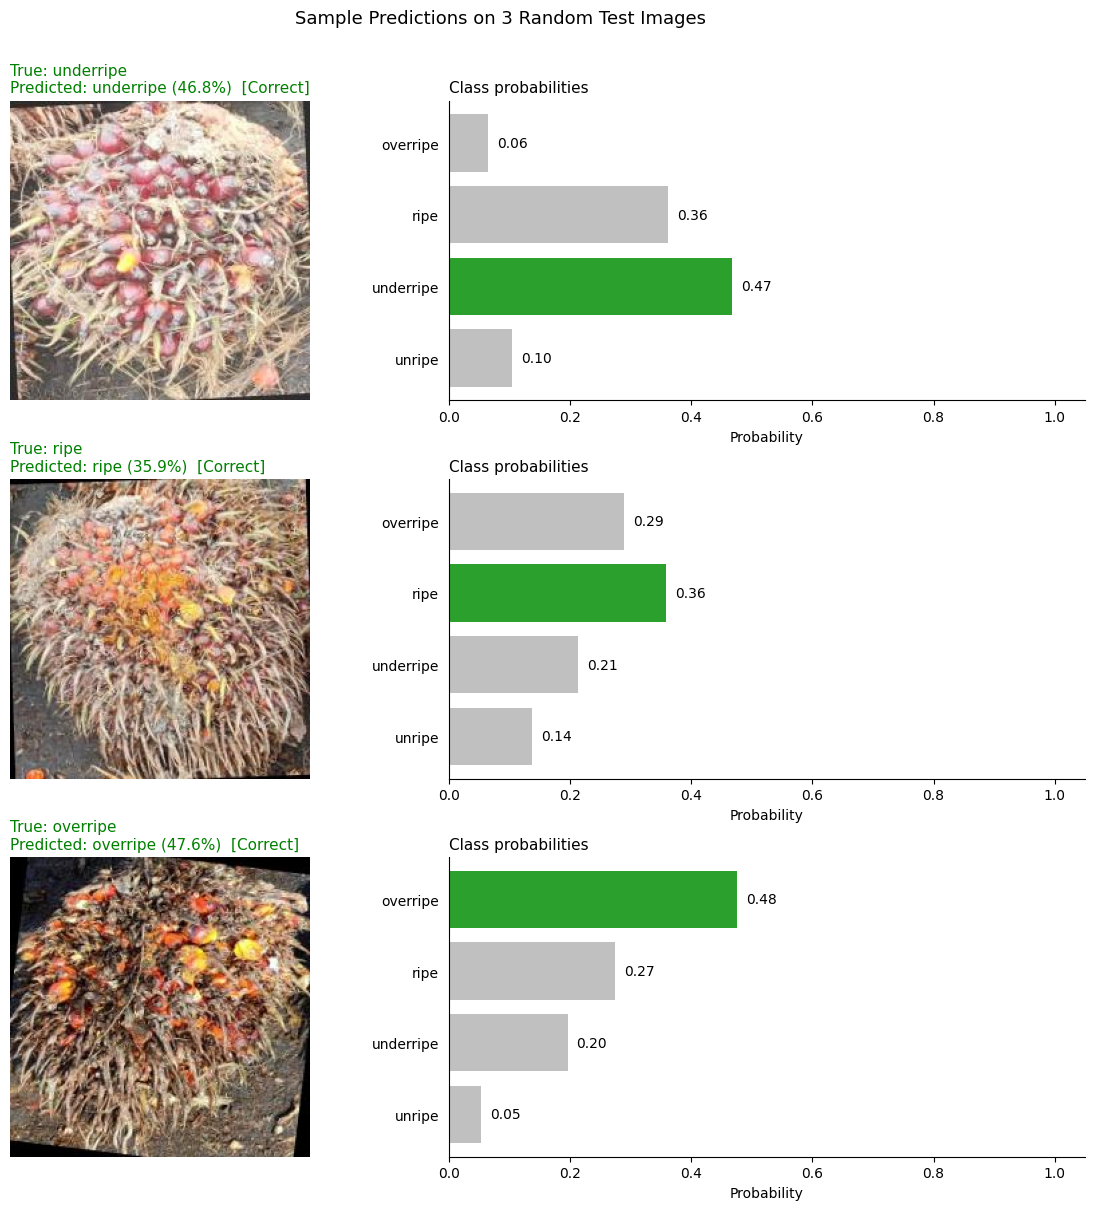

In [14]:
# What this cell does:
#   - Picks 3 random images from the test set
#   - Runs them through the trained model
#   - Shows each image side-by-side with a probability bar chart
#   - Color-codes the result: green for correct, red for wrong
# Self-contained: works even after a runtime restart.

import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input


# ---- Constants (re-defined so the cell is self-contained) ------------------
CLASS_NAMES = ["overripe", "ripe", "underripe", "unripe"]
IMG_SIZE    = (224, 224)
VALID_EXTS  = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}



# ---- Load model if not already in memory -----------------------------------
try:
    final_model
    print("Using model already in memory.")
except NameError:
    print(f"Loading model locally...")
    final_model = model
    print("Loaded.")


# ---- Locate the test directory (prefer the fast local copy) ----------------
if True:
    TEST_DIR = "dataset/palm-fruit-ripeness-classificationcnn.v1i.folder/test"
else:
    TEST_DIR = "dataset/palm-fruit-ripeness-classificationcnn.v1i.folder/test"


# ---- Pick N random test images ---------------------------------------------
N_SAMPLES = 3   # change to 5 or 10 if you want more

all_samples = []
for cls_idx, cls in enumerate(CLASS_NAMES):
    cls_dir = os.path.join(TEST_DIR, cls)
    for f in os.listdir(cls_dir):
        if os.path.splitext(f)[1].lower() in VALID_EXTS:
            all_samples.append((os.path.join(cls_dir, f), cls_idx, cls))

# Different samples each run. To make it deterministic, set random.seed(42).
samples = random.sample(all_samples, N_SAMPLES)


# ---- Predict + Visualize ---------------------------------------------------
fig, axes = plt.subplots(
    N_SAMPLES, 2,
    figsize=(12, 4 * N_SAMPLES),
    gridspec_kw={"width_ratios": [1, 1.3]},
)
if N_SAMPLES == 1:
    axes = np.array([axes])

for i, (img_path, true_idx, true_cls) in enumerate(samples):
    # 1. Load image at the model's expected input size
    img      = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
    img_arr  = tf.keras.utils.img_to_array(img)                # (224, 224, 3) in [0, 255]
    img_pre  = preprocess_input(img_arr.copy())                # rescale to [-1, 1]
    img_in   = np.expand_dims(img_pre, axis=0)                 # add batch dimension

    # 2. Predict
    probs      = final_model.predict(img_in, verbose=0)[0]
    pred_idx   = int(np.argmax(probs))
    pred_cls   = CLASS_NAMES[pred_idx]
    confidence = float(probs[pred_idx])
    correct    = (pred_idx == true_idx)

    # 3. Left subplot — the image
    ax_img = axes[i, 0]
    ax_img.imshow(img_arr.astype("uint8"))
    ax_img.axis("off")

    verdict = "Correct" if correct else "Wrong"
    color   = "green"   if correct else "red"
    ax_img.set_title(
        f"True: {true_cls}\n"
        f"Predicted: {pred_cls} ({confidence*100:.1f}%)  [{verdict}]",
        color=color, fontsize=11, loc="left",
    )

    # 4. Right subplot — class probabilities (horizontal bar chart)
    ax_bar = axes[i, 1]
    bar_colors = []
    for j in range(len(CLASS_NAMES)):
        if j == true_idx:
            bar_colors.append("#2ca02c")            # green = true class
        elif j == pred_idx and not correct:
            bar_colors.append("#d62728")            # red = wrong prediction
        else:
            bar_colors.append("#c0c0c0")            # gray = other classes

    bars = ax_bar.barh(CLASS_NAMES, probs, color=bar_colors)
    ax_bar.set_xlim(0, 1.05)
    ax_bar.set_xlabel("Probability")
    ax_bar.set_title("Class probabilities", fontsize=11, loc="left")
    for bar, p in zip(bars, probs):
        ax_bar.text(p + 0.015, bar.get_y() + bar.get_height() / 2,
                    f"{p:.2f}", va="center", fontsize=10)
    ax_bar.invert_yaxis()
    ax_bar.spines["top"].set_visible(False)
    ax_bar.spines["right"].set_visible(False)
    ax_bar.tick_params(left=False)

plt.suptitle(f"Sample Predictions on {N_SAMPLES} Random Test Images",
             fontsize=13, y=1.005)
plt.tight_layout()
plt.show()


## Lighting Evaluation


In [15]:
# =============================================================
# Lighting Evaluation (FIXED)
# =============================================================
import tensorflow as tf

print("Evaluating under varying lighting conditions...")

# FIXED: Added value_range=(-1.0, 1.0) so it scales properly!
simulate_dark = tf.keras.Sequential([tf.keras.layers.RandomBrightness(factor=(-0.3, -0.3), value_range=(-1.0, 1.0))])
simulate_bright = tf.keras.Sequential([tf.keras.layers.RandomBrightness(factor=(0.3, 0.3), value_range=(-1.0, 1.0))])

test_ds_dark = test_ds.map(lambda x, y: (simulate_dark(x, training=True), y))
test_ds_bright = test_ds.map(lambda x, y: (simulate_bright(x, training=True), y))

print("\n--- Original Test Set ---")
loss, acc = model.evaluate(test_ds)

print("\n--- Darkened Test Set (-30%) ---")
loss_dark, acc_dark = model.evaluate(test_ds_dark)

print("\n--- Brightened Test Set (+30%) ---")
loss_bright, acc_bright = model.evaluate(test_ds_bright)

print(f"\nSummary of Accuracy:")
print(f"Original : {acc:.4f}")
print(f"Darkened : {acc_dark:.4f}")
print(f"Brightened: {acc_bright:.4f}")



Evaluating under varying lighting conditions...

--- Original Test Set ---
17/17 ━━━━━━━━━━━━━━━━━━━━ 6s 360ms/step - accuracy: 0.6814 - loss: 0.1280

--- Darkened Test Set (-30%) ---
17/17 ━━━━━━━━━━━━━━━━━━━━ 6s 360ms/step - accuracy: 0.6775 - loss: 0.1248

--- Brightened Test Set (+30%) ---
17/17 ━━━━━━━━━━━━━━━━━━━━ 6s 350ms/step - accuracy: 0.6545 - loss: 0.1316

Summary of Accuracy:
Original : 0.6814
Darkened : 0.6775
Brightened: 0.6545
